# Exercício · Teste A/B do onboarding da Aprendiz

**Disciplina 4 · Testes de Hipótese e Experimentação · Pós-graduação em Ciência de Dados e IA · UNIPDS**

Neste exercício vamos percorrer a anatomia completa de um teste A/B, do planejamento à decisão:

1. **Planejar:** hipóteses, α, poder e MDE, combinados antes de olhar os dados;
2. **Entender o estado atual** do processo com uma EDA do histórico;
3. **Checar o TLC e calcular o tamanho mínimo de amostra** (em Python e no G\*Power);
4. **Analisar o experimento** com as duas lentes da aula: intervalo de confiança e teste de hipótese (multiverso de H0, p-valor);
5. **Escolher o teste certo** para cada métrica: z e t para uma amostra, z para duas proporções e t de Welch (e entender por que os testes de variância não servem aqui);
6. **Separar significância estatística de prática** e tomar a decisão.

Vamos trabalhar com uma **proporção** (conversão) e uma **média** (receita por usuário). **Todos os testes são bicaudais.**

### Como usar este notebook

Cada passo tem um **prompt**, escrito em linguagem de estatística, não de programação: ele diz **o que** a análise precisa fazer, não **como** codificar. Use sempre a mesma conversa com a IA, para ela lembrar dos passos anteriores. Copie o prompt, cole na IA, **leia o código** que ela gerar antes de rodar (ele faz o que o prompt pediu? os números fazem sentido?), cole na célula de código, rode e interprete o resultado. As fórmulas ficam no texto para explicar a lógica.

## O contexto

A **Aprendiz** é uma plataforma de cursos online. O usuário se cadastra, ganha **7 dias grátis** para experimentar as aulas e, se gostar, **compra cursos** avulsos. O catálogo tem cursos de R$ 97, R$ 147, R$ 197 e R$ 297, e um usuário pode comprar mais de um.

O time de Produto criou um **onboarding novo, a "trilha guiada"**, que aparece durante os 7 dias grátis: um módulo introdutório com um guia sobre o curso. A aposta é que um usuário que engaja no período grátis compra mais depois. A pergunta de negócio é: **a trilha guiada aumenta as vendas?**

**O desenho do teste**

| Peça | Decisão |
|:---|:---|
| População | Usuários que se cadastram na plataforma  |
| Unidade sorteada | O **usuário**, sorteado no cadastro: 50% controle (onboarding atual), 50% tratamento (trilha guiada) |
| Métrica primária (proporção) | `comprou_30d`: percentual de usuários que fez pelo menos 1 compra nos 30 dias após o cadastro. É atribuido o número 1 se fez a compra, 0 caso contrário |
| Métrica secundária (média) | `receita_30d`: quanto os usuários gastaram em média (R$) nos 30 dias após o cadastro, em cada grupo **0 para quem não comprou** |
| Métrica de diagnóstico | `concluiu_aula1_7d`: 1 se o usuário concluiu a primeira aula dos cursos PAGOS dentro dos 7 dias grátis |

**Por que essas métricas são “limpas”.** As três são calculadas para **todo usuário sorteado**, numa janela fixa a partir do cadastro de cada um. Ninguém fica de fora da conta: quem não comprou entra com 0 na receita. A unidade de análise é a unidade sorteada (o usuário), e nenhuma delas é uma razão.


**Por que 30 dias.** O onboarding age nos 7 dias grátis, mas a compra pode vir depois. Uma janela de 30 dias captura a decisão de compra. O preço disso: cada usuário precisa de 30 dias de acompanhamento antes de entrar na análise. Métricas de negócio são mais lentas que métricas de engajamento.

**Métrica de diagnóstico: conclusão da 1ª aula em 7 dias**

A trilha guiada não vende cursos diretamente. Ela age no período grátis, ajudando o usuário a engajar logo na primeira semana. A aposta do time é uma cadeia de causa e efeito:

> trilha guiada → mais usuários concluem a 1ª aula de algum dos cursos pagos nos 7 dias grátis → mais usuários compram

A conclusão da 1ª aula mede o **elo do meio** dessa cadeia. Ela responde se a trilha fez o que foi desenhada para fazer. Se a conclusão não mudar, o onboarding falhou já no primeiro passo, e qualquer mudança na conversão precisa ser olhada com desconfiança.

**1. Ela confirma se a trilha fez o que prometeu.** O módulo extra existe para despertar interesse pelos cursos pagos. Se ele funciona, mais gente deveria ir olhar esses cursos. A conclusão da primeira aula é o sinal mais direto desse interesse, porque ninguém compra sem antes olhar o curso. Ela mede o passo que liga "vi o módulo" a "comprei".

**2. Ela ajuda a separar onde a trilha falhou ou funcionou.** Combinando com a conversão:

| Conclusão aula | Conversão | Leitura |
|---|---|---|
| sobem | sobe | a trilha funcionou como planejado |
| sobem | não muda | a trilha desperta interesse, mas algo trava na página do curso (preço, descrição, checkout) |
| não mudam | sobe | a trilha vende por outro caminho, e vale investigar qual |
| não mudam | não muda | o módulo não despertou interesse nenhum |

Sem a métrica do meio, um "a conversão não mudou" não diz onde o problema está. Com ela, o time sabe se precisa mexer na trilha ou na página do curso.

**3. Ela responde rápido.** A conversão leva 30 dias para ser medida, e a visita sai em 7. Na primeira semana o time já sabe se o módulo está gerando interesse. Se não estiver, dá para investigar antes de esperar o mês inteiro.

Ela não decide sozinha: mais visitas sem mais compras não pagam a trilha. Ela explica o resultado da métrica que decide, que é a conversão.


## Parte 0 · Preparação

**Prompt para a IA**

> Vou analisar um teste A/B em Python. Prepare o ambiente com as bibliotecas que vamos usar para manipular dados, fazer gráficos e fazer estatística (testes de hipótese, intervalos de confiança e cálculo de poder e tamanho de amostra). Sempre que possível, use funções prontas dessas bibliotecas em vez de implementar fórmulas à mão, e escreva um código simples, para iniciantes.
> Deixe definidos os parâmetros do estudo: nível de significância de 5%, poder de 80%, menor efeito que importa (MDE) de 1,5 ponto percentual na conversão e de R$ 3 na receita por usuário.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import NormalIndPower, TTestIndPower
from statsmodels.stats.proportion import (proportion_confint, proportions_ztest,
                                          confint_proportions_2indep, proportion_effectsize)

ALPHA = 0.05           # nível de significância
PODER = 0.80           # poder desejado
MDE_CONV = 0.015       # 1,5 ponto percentual na conversão
MDE_REC = 3.0          # R$ 3 na receita por usuário

**Prompt para a IA**

> Carregue o arquivo historico_cadastros.csv em um dataframe chamado hist. Mostre as primeiras linhas do histórico, o shape e os tipos das colunas

In [ ]:
hist = pd.read_csv(r"C:\Users\renat\Downloads\historico_cadastros.csv") #troque o nome aqui
print(hist.dtypes)
print(hist.shape)
hist.head()

user_id                  object
data_cadastro            object
dispositivo              object
canal                    object
concluiu_aula1_7d         int64
comprou_30d               int64
cursos_comprados_30d      int64
receita_30d             float64
dtype: object
(121628, 8)


,user_id,data_cadastro,dispositivo,canal,concluiu_aula1_7d,comprou_30d,cursos_comprados_30d,receita_30d
0,U100000,2026-06-01,web,pago,1,0,0,0.0
1,U100001,2026-06-01,ios,pago,0,0,0,0.0
2,U100002,2026-06-01,ios,organico,1,0,0,0.0
3,U100003,2026-06-01,web,organico,0,0,0,0.0
4,U100004,2026-06-01,ios,organico,0,0,0,0.0


**Prompt para a IA**

>  A coluna data_cadastro é uma data, passe para datetime. Mostre as primeiras linhas do histórico depois da transformação

In [ ]:
hist["data_cadastro"] = pd.to_datetime(hist["data_cadastro"])
hist.dtypes

user_id                         object
data_cadastro           datetime64[ns]
dispositivo                     object
canal                           object
concluiu_aula1_7d                int64
comprou_30d                      int64
cursos_comprados_30d             int64
receita_30d                    float64
dtype: object

## Parte 1 · As hipóteses e os riscos

Antes de olhar qualquer dado, o time combinou:

| Ingrediente | Valor | Por quê |
|:---|:---|:---|
| Hipóteses (primária) | H0: p_trat = p_ctrl · Ha: p_trat ≠ p_ctrl | Bilateral: se a trilha piorar a conversão, queremos saber |
| Hipóteses (secundária) | H0: μ_trat = μ_ctrl · Ha: μ_trat ≠ μ_ctrl | Bilateral, pelo mesmo motivo |
| α | 5% | Risco aceito de lançar uma trilha que não muda nada (erro tipo I) |
| Poder | 80% | Chance de enxergar o efeito mínimo, se ele existir (β = 20%) |
| MDE da conversão | +1,5 p.p. | Menor ganho que paga o custo de manter a trilha |
| MDE da receita | +R$ 3 por usuário | Menor ganho de receita que paga a trilha |

O que **ainda falta** para calcular o tamanho de amostra é a **variabilidade** das métricas, e precisamos saber se elas se comportam bem o bastante para o TLC. As duas coisas vêm do histórico.

## Parte 2 · O estado atual do processo (EDA)

O arquivo `historico_cadastros.csv` tem os usuários que se cadastraram nas **8 semanas anteriores** ao teste, todos com o onboarding atual e todos com os 30 dias de acompanhamento completos.

### 2.1 Quantos usuários chegam por dia?

**Prompt para a IA**

> No histórico, quero entender o fluxo de usuários: qual é o período coberto, quantos usuários há no total e quantos cadastros acontecem por dia (média, mínimo e máximo). Mostre também um gráfico dos cadastros ao longo dos dias.

Período: 2026-06-01 a 2026-07-26
Usuários: 121628
Usuários únicos: 121628
Cadastros por dia: média 2172 · mínimo 1629 · máximo 2681


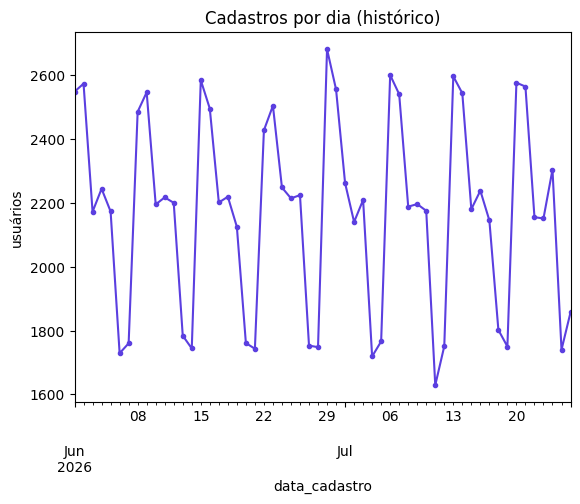

In [ ]:
print("Período:", hist["data_cadastro"].min().date(), "a", hist["data_cadastro"].max().date())
print("Usuários:", len(hist))
print("Usuários únicos:", hist["user_id"].nunique())

por_dia = hist.groupby("data_cadastro").size()
print(f"Cadastros por dia: média {por_dia.mean():.0f} · mínimo {por_dia.min()} · máximo {por_dia.max()}")

por_dia.plot(marker="o", markersize=3, color="#5B3FE0")
plt.title("Cadastros por dia (histórico)")
plt.ylabel("usuários")
plt.show()

> **Prompt.** Gere o codigo para verificar se as quedas de cadastros por dia realmente acontecem no fim de semana.

In [ ]:
por_dia

data_cadastro
2026-06-01    2548
2026-06-02    2573
2026-06-03    2172
2026-06-04    2244
2026-06-05    2173
2026-06-06    1729
2026-06-07    1760
2026-06-08    2485
2026-06-09    2546
2026-06-10    2195
2026-06-11    2217
2026-06-12    2200
2026-06-13    1784
2026-06-14    1744
2026-06-15    2584
2026-06-16    2495
2026-06-17    2201
2026-06-18    2219
2026-06-19    2125
2026-06-20    1761
2026-06-21    1743
2026-06-22    2427
2026-06-23    2504
2026-06-24    2248
2026-06-25    2214
2026-06-26    2224
2026-06-27    1753
2026-06-28    1748
2026-06-29    2681
2026-06-30    2555
2026-07-01    2262
2026-07-02    2140
2026-07-03    2209
2026-07-04    1719
2026-07-05    1766
2026-07-06    2600
2026-07-07    2540
2026-07-08    2188
2026-07-09    2196
2026-07-10    2175
2026-07-11    1629
2026-07-12    1751
2026-07-13    2596
2026-07-14    2543
2026-07-15    2180
2026-07-16    2238
2026-07-17    2145
2026-07-18    1802
2026-07-19    1750
2026-07-20    2576
2026-07-21    2564
2026-07-22    215

seg    2562.0
ter    2540.0
qua    2200.0
qui    2202.0
sex    2194.0
sáb    1740.0
dom    1765.0
Name: cadastros, dtype: float64


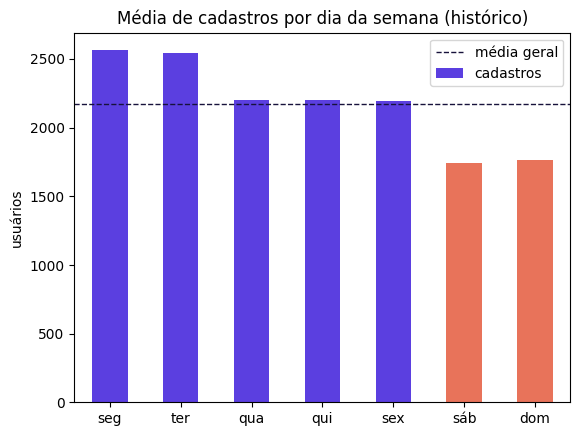


Dias úteis: 2340/dia
Fim de semana: 1752/dia


In [ ]:
# Dia da semana de cada data (0 = segunda ... 6 = domingo)
dias = pd.DataFrame({"cadastros": por_dia})
dias["dia_semana"] = dias.index.dayofweek
dias["fim_de_semana"] = dias["dia_semana"] >= 5

# Média de cadastros por dia da semana
nomes = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
media_dia = dias.groupby("dia_semana")["cadastros"].mean()
media_dia.index = nomes
print(media_dia.round(0))

media_dia.plot.bar(color=["#5B3FE0"] * 5 + ["#E8735A"] * 2)
plt.axhline(por_dia.mean(), color="#17123B", linestyle="--", linewidth=1, label="média geral")
plt.title("Média de cadastros por dia da semana (histórico)")
plt.ylabel("usuários")
plt.xticks(rotation=0)
plt.legend()
plt.show()

# Dias úteis x fim de semana: t de Welch, bicaudal
uteis = dias.loc[~dias["fim_de_semana"], "cadastros"]
fds = dias.loc[dias["fim_de_semana"], "cadastros"]


print(f"\nDias úteis: {uteis.mean():.0f}/dia")
print(f"Fim de semana: {fds.mean():.0f}/dia")


> **Leitura.** Repare no padrão semanal: segundas e terças têm mais cadastros, fins de semana têm menos. É um dos motivos para rodar o teste em **semanas completas**.

### 2.2 A métrica primária: conversão em 30 dias

Para uma métrica binária, a estimativa é a taxa e o IC é o de uma proporção. Usamos o método de Wilson; com amostras deste tamanho, o de Wald daria praticamente o mesmo resultado.

**Prompt para a IA**

> No histórico, calcule a taxa de conversão em 30 dias (comprou pelo menos um curso), que é a nossa métrica primária. Mostre o intervalo de confiança de 95% pelo método de Wilson.

In [ ]:
x0 = hist["comprou_30d"].sum()
n0 = len(hist)
p0 = x0 / n0
ic_p0 = proportion_confint(x0, n0, alpha=ALPHA, method="wilson")
print(f"Conversão atual: {p0:.2%}  ·  IC 95% (Wilson): {ic_p0[0]:.2%} a {ic_p0[1]:.2%}")


Conversão atual: 11.46%  ·  IC 95% (Wilson): 11.28% a 11.64%


**Prompt para a IA**

> Quero saber se a conversão do histórico é estável ao longo do tempo e se ela muda conforme o perfil do usuário. Mostre a taxa de conversão por semana de cadastro (com o número de usuários de cada semana), por canal de aquisição e por dispositivo.

In [ ]:
semana = hist["data_cadastro"].dt.to_period("W")
print(hist.groupby(semana)["comprou_30d"].agg(["mean", "count"]))
print()
print(hist.groupby("canal")["comprou_30d"].mean())
print()
print(hist.groupby("dispositivo")["comprou_30d"].mean())

                           mean  count
data_cadastro                         
2026-06-01/2026-06-07  0.112968  15199
2026-06-08/2026-06-14  0.119372  15171
2026-06-15/2026-06-21  0.114027  15128
2026-06-22/2026-06-28  0.113639  15118
2026-06-29/2026-07-05  0.115380  15332
2026-07-06/2026-07-12  0.117581  15079
2026-07-13/2026-07-19  0.112823  15254
2026-07-20/2026-07-26  0.111031  15347

canal
indicacao    0.161757
organico     0.120766
pago         0.090421
Name: comprou_30d, dtype: float64

dispositivo
android    0.106831
ios        0.125900
web        0.118717
Name: comprou_30d, dtype: float64


> **Leitura.** A conversão está por volta de **11,5%** e é estável semana a semana. Ela muda bastante entre canais (indicação converte mais, mídia paga menos). Isso não é um problema para o teste: o sorteio vai distribuir canais e dispositivos de forma parecida entre os grupos. Mas é por isso que **não** dá para comparar períodos diferentes sem sorteio: uma mudança no mix de canais mudaria a conversão sem nenhuma mudança no produto.

**Comparando as conversões por canal de aquisição**

Quando a pergunta é sobre a **diferença** entre duas proporções (canal A − canal B, tratamento − controle), temos 2 opções: Wald e Newcombe.

O **Newcombe** é a versão robusta: ele calcula o intervalo de Wilson de cada grupo e combina os dois. Ou seja, o Newcombe está para a diferença assim como o Wilson está para uma proporção.

| Para | Simples | Robusto |
|:---|:---|:---|
| Uma proporção | Wald | Wilson |
| Diferença de duas proporções | Wald | Newcombe |

**Na prática:** com amostras grandes e taxas longe dos extremos, as duas versões coincidem. A versão robusta faz diferença em amostras pequenas (um piloto com 20 empresas) ou em eventos raros (uma taxa de fraude de 0,3%). Como ela nunca é pior, é uma boa escolha padrão. O Wald continua útil para entender a lógica e fazer a conta à mão.

> **Prompt:** Quero comparar a conversão em 30 dias entre os canais de aquisição, no histórico, para saber se as diferenças são reais. Mostre, para cada canal, o número de usuários, de compradores e a taxa de conversão.
> Depois compare os canais dois a dois: para cada par, calcule a diferença de conversão em pontos percentuais e o intervalo de confiança de 95% da diferença pelo método de Wald. Mostre tudo numa tabela e faça um gráfico com o intervalo de confiança de cada diferença e uma linha no zero.

           compradores  usuarios  conversao
canal                                      
indicacao         2921     18058   0.161757
organico          6575     54444   0.120766
pago              4442     49126   0.090421
             comparação  diferença (p.p.)  IC 95% inf  IC 95% sup
0  indicacao − organico          4.099027    3.501406    4.707036
1      indicacao − pago          7.133601    6.544781    7.732696
2       organico − pago          3.034574    2.661190    3.407531


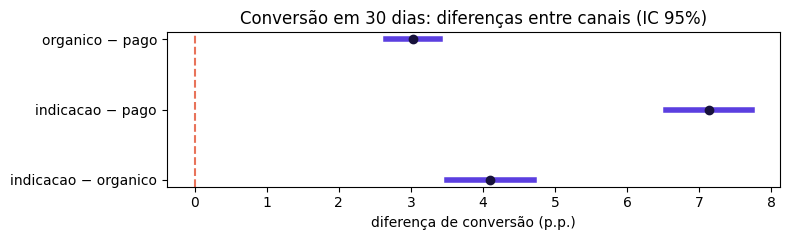

In [ ]:
import itertools

# Conversão, compradores e usuários por canal
resumo = hist.groupby("canal")["comprou_30d"].agg(compradores="sum", usuarios="count")
resumo["conversao"] = resumo["compradores"] / resumo["usuarios"]
print(resumo)

# Comparações par a par: diferença e IC 95% (Wald)
linhas = []
for a, b in itertools.combinations(resumo.index, 2):
    xa, na = resumo.loc[a, "compradores"], resumo.loc[a, "usuarios"]
    xb, nb = resumo.loc[b, "compradores"], resumo.loc[b, "usuarios"]
    lo, hi = confint_proportions_2indep(xa, na, xb, nb, method="newcombe")
    linhas.append({"comparação": f"{a} − {b}",
                   "diferença (p.p.)": (xa / na - xb / nb) * 100,
                   "IC 95% inf": lo * 100,
                   "IC 95% sup": hi * 100})

pares = pd.DataFrame(linhas)
print(pares)

# Gráfico dos ICs das diferenças
fig, ax = plt.subplots(figsize=(8, 2.5))
for i, linha in pares.iterrows():
    ax.plot([linha["IC 95% inf"], linha["IC 95% sup"]], [i, i], color="#5B3FE0", linewidth=4)
    ax.plot(linha["diferença (p.p.)"], i, "o", color="#17123B")
ax.axvline(0, color="#E8735A", linestyle="--")
ax.set_yticks(range(len(pares)))
ax.set_yticklabels(pares["comparação"])
ax.set_xlabel("diferença de conversão (p.p.)")
ax.set_title("Conversão em 30 dias: diferenças entre canais (IC 95%)")
plt.tight_layout()
plt.show()

### 2.3 A métrica secundária: receita por usuário em 30 dias

**Prompt para a IA**

> Agora a receita por usuário em 30 dias, no histórico. Quero a média com o intervalo de confiança de 95%, o desvio-padrão, a porcentagem de usuários com receita zero e os percentis 25, 50, 75, 90 e 95. Mostre um gráfico da distribuição da receita.

Média: R$ 27.12  ·  IC 95%: R$ 26.63 a R$ 27.62
Desvio-padrão: R$ 87.71
Usuários com receita zero: 88.5%
Percentis:
0.25      0.0
0.50      0.0
0.75      0.0
0.90     97.0
0.95    197.0
Name: receita_30d, dtype: float64


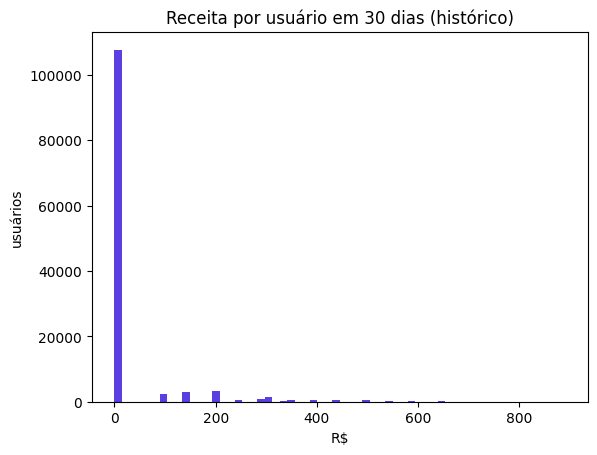

In [ ]:
receita = hist["receita_30d"]
mu0 = receita.mean()
sigma0 = receita.std()
ic_mu0 = stats.ttest_1samp(receita, popmean=0).confidence_interval(confidence_level=1 - ALPHA)

print(f"Média: R$ {mu0:.2f}  ·  IC 95%: R$ {ic_mu0.low:.2f} a R$ {ic_mu0.high:.2f}")
print(f"Desvio-padrão: R$ {sigma0:.2f}")
print(f"Usuários com receita zero: {(receita == 0).mean():.1%}")
print("Percentis:")
print(receita.quantile([0.25, 0.50, 0.75, 0.90, 0.95]))

receita.plot.hist(bins=60, color="#5B3FE0")
plt.title("Receita por usuário em 30 dias (histórico)")
plt.xlabel("R$")
plt.ylabel("usuários")
plt.show()

> **Leitura.** A receita média é de cerca de **R$ 27 por usuário**, mas quase ninguém gasta R$ 27: **~88% dos usuários não compram nada**, então os percentis 25, 50 e 75 são todos zero. O percentil 90 é o curso mais barato (R$ 97) e o 95, cerca de R$ 197. A média é puxada por uma cauda longa de quem compra vários cursos. O desvio-padrão (~R$ 88) é **mais de três vezes a média**. Essas duas características (muita assimetria e muito ruído) vão pesar no tamanho de amostra.

### 2.4 Diagnóstico: ativação e compra

A trilha guiada age no engajamento dos 7 dias grátis. Vale olhar se esse engajamento tem relação com a compra.

**Prompt para a IA**

> No histórico, calcule a taxa de conclusão da primeira aula nos 7 dias grátis, com o intervalo de confiança de 95% de Wilson. Depois compare a taxa de conversão entre quem concluiu e quem não concluiu a primeira aula e a taxa de conclusão da primeira aula em quem converteu e não converteu

In [ ]:
x_at, n_at = hist["concluiu_aula1_7d"].sum(), len(hist)
ic_at = proportion_confint(x_at, n_at, alpha=ALPHA, method="wilson")
print(f"Conclusão da 1ª aula: {x_at / n_at:.2%}  ·  IC 95%: {ic_at[0]:.2%} a {ic_at[1]:.2%}")
print()
print(hist.groupby("concluiu_aula1_7d")["comprou_30d"].mean())
print(hist.groupby("comprou_30d")["concluiu_aula1_7d"].mean())

Conclusão da 1ª aula: 30.48%  ·  IC 95%: 30.23% a 30.74%

concluiu_aula1_7d
0    0.044222
1    0.275076
Name: comprou_30d, dtype: float64
comprou_30d
0    0.249587
1    0.731741
Name: concluiu_aula1_7d, dtype: float64


> **Leitura.**
>
> **1. A maioria não ativa.** Só cerca de **30,5%** dos usuários concluem a primeira aula nos 7 dias grátis, com IC de 30,2% a 30,7%. Sete em cada dez passam pelo período grátis sem terminar nem a primeira aula.
>
> **2. Quem ativa compra muito mais.** Entre quem concluiu a aula, **27,5%** compram em 30 dias; entre quem não concluiu, só **4,4%**. A conversão de quem ativa é mais de 6 vezes maior.
>
> **3. Quase todo comprador passou pela primeira aula.** Entre os compradores, **73%** tinham concluído a aula; entre os que não compraram, só **25%**. A primeira aula é praticamente uma etapa do caminho até a compra.
>
> **4. As duas leituras são complementares.** A primeira olha para a frente: P(compra | concluiu), quem conclui tem mais chance de comprar. A segunda olha para trás: P(concluiu | compra), quem compra quase sempre concluiu. As duas apontam para o mesmo lugar: **a ativação no período grátis é o ponto crítico do funil**, e é isso que motiva testar um onboarding que leve mais gente a concluir a primeira aula.
>
> **Cuidado:** é uma associação no histórico, não um efeito causal. Quem conclui a aula pode ser quem já chegou com mais intenção de comprar. Se aumentarmos a conclusão, quanto a compra sobe? Só o teste A/B responde.

## Parte 3 · Tamanho mínimo de amostra

### 3.1 Primeiro, o piso do TLC: a regra de Kohavi

O cálculo de tamanho de amostra usa os quantis da Normal (o 1,96 e o 0,84). Ele **pressupõe** que a média de cada grupo se comporta como Normal, ou seja, que o TLC já funcionou. Quanto mais assimétrica a métrica, mais dados o TLC precisa. A regra de Kohavi dá esse piso:

$$n > 355 \times \gamma^2 \qquad\qquad \gamma = \frac{E[(X-\mu)^3]}{\sigma^3}$$

γ é a assimetria da métrica. Ela não tem unidade: não depende da escala, só da **forma** da distribuição. Para uma taxa, ela vem da própria p: γ = (1 − 2p)/√(p(1 − p)). Abaixo desse n, nenhum cálculo baseado na Normal é confiável.

**Prompt para a IA**

> Antes de calcular o tamanho de amostra, quero saber o piso que o Teorema do Limite Central exige para cada métrica, pela regra de Kohavi: n > 355 × assimetria². Calcule a assimetria da conversão e da receita por usuário no histórico e o n mínimo por grupo que a regra pede para cada uma.

In [ ]:
assim_conv = stats.skew(hist["comprou_30d"])
assim_rec = stats.skew(hist["receita_30d"])
n_kohavi_conv = 355 * assim_conv**2
n_kohavi_rec = 355 * assim_rec**2

print(f"Conversão: assimetria = {assim_conv:.2f}  ·  Kohavi pede n > {n_kohavi_conv:.0f} por grupo")
print(f"Receita:   assimetria = {assim_rec:.2f}  ·  Kohavi pede n > {n_kohavi_rec:.0f} por grupo")

Conversão: assimetria = 2.42  ·  Kohavi pede n > 2079 por grupo
Receita:   assimetria = 3.92  ·  Kohavi pede n > 5457 por grupo


> **Leitura.** A receita, com ~88% de zeros e cauda longa, tem assimetria ~3,9: o TLC só funciona a partir de ~5.500 usuários por grupo. A conversão (~11,5%) também é assimétrica, porque é uma taxa baixa, e pede ~2.100. Esses são os **pisos**. Se o cálculo de poder pedir menos que isso, o piso manda. A regra é conservadora para testes A/B com grupos do mesmo tamanho (a assimetria das duas médias tende a se cancelar na diferença), então ela funciona como uma margem de segurança.

### 3.2 Proporção: conversão

$$n = \frac{(z_{1-\alpha/2} + z_{1-\beta})^2 \, [p_1(1-p_1) + p_2(1-p_2)]}{(p_2 - p_1)^2}$$

O statsmodels (assim como o G\*Power) usa a versão arco-seno, com o **h de Cohen**: h = 2·arcsen√p₂ − 2·arcsen√p₁. A diferença para a fórmula acima é de poucos usuários.

**Prompt para a IA**

> Quero calcular o tamanho mínimo de amostra por grupo para o teste A/B da conversão. A taxa atual é a que calculamos no histórico, arredondada para 3 casas (≈ 11,5%), e o menor aumento que nos interessa detectar é de 1,5 ponto percentual (para ≈ 13,0%). Use nível de significância de 5%, poder de 80%, teste bicaudal e grupos do mesmo tamanho. Mostre as duas taxas, o tamanho do efeito usado no cálculo e o número de usuários por grupo.

In [ ]:
p0

np.float64(0.11459532344525931)

In [ ]:
p1 = round(p0, 3)
p2 = p1 + MDE_CONV

h = proportion_effectsize(p2, p1)
n_conv = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=PODER, ratio=1)

print(f"p1 = {p1:.3f} · p2 = {p2:.3f} · h = {h:.4f}")
print(f"n por grupo (conversão): {n_conv:.0f}")

p1 = 0.115 · p2 = 0.130 · h = 0.0458
n por grupo (conversão): 7493


**No G\*Power**

| Campo | Valor |
|:---|:---|
| Test family | z tests |
| Statistical test | Proportions: Difference between two independent proportions |
| Type of power analysis | A priori: Compute required sample size |
| Tail(s) | Two |
| Proportion p2 | 0.130 |
| Proportion p1 | 0.115 |
| α err prob | 0.05 |
| Power (1−β err prob) | 0.80 |
| Allocation ratio N2/N1 | 1 |

### 3.3 Média: receita por usuário

$$n = \frac{2\sigma^2 (z_{1-\alpha/2} + z_{1-\beta})^2}{\text{MDE}^2} \qquad\qquad d = \frac{\text{MDE}}{\sigma}$$

O G\*Power e o statsmodels pedem o efeito padronizado, o **d de Cohen**. O σ vem do histórico.

**Prompt para a IA**

> Agora calcule o tamanho mínimo de amostra por grupo para a receita por usuário. O menor aumento que importa é de R$ 3, e o desvio-padrão vem do histórico. Use nível de significância de 5%, poder de 80%, teste bicaudal e grupos do mesmo tamanho. Mostre o desvio usado, o tamanho do efeito padronizado (d de Cohen) e o número de usuários por grupo.

In [ ]:
d = MDE_REC / sigma0
n_rec = TTestIndPower().solve_power(effect_size=d, alpha=ALPHA, power=PODER, ratio=1)

print(f"σ = R$ {sigma0:.2f} · MDE = R$ {MDE_REC} · d = {d:.4f}")
print(f"n por grupo (receita): {n_rec:.0f}")

σ = R$ 87.71 · MDE = R$ 3.0 · d = 0.0342
n por grupo (receita): 13418


**No G\*Power**

| Campo | Valor |
|:---|:---|
| Test family | t tests |
| Statistical test | Means: Difference between two independent means (two groups) |
| Type of power analysis | A priori: Compute required sample size |
| Tail(s) | Two |
| Effect size d | o `d` calculado acima (≈ 0.0342) |
| α err prob | 0.05 |
| Power (1−β err prob) | 0.80 |
| Allocation ratio N2/N1 | 1 |

O G\*Power não sabe calcular o σ: ele vem do histórico, e o `d` é calculado antes.

### 3.4 O tamanho do teste e a duração

**Prompt para a IA**

> Junte tudo: o teste precisa respeitar o piso de Kohavi das duas métricas e ter poder para as duas. Defina o número de usuários por grupo como o maior entre os quatro valores calculados, o total de usuários e quantos dias o teste precisa rodar, considerando a média de cadastros por dia do histórico. Arredonde a duração para semanas completas. Mostre uma tabela com os quatro valores para eu ver qual deles manda.

In [ ]:
por_dia

data_cadastro
2026-06-01    2548
2026-06-02    2573
2026-06-03    2172
2026-06-04    2244
2026-06-05    2173
2026-06-06    1729
2026-06-07    1760
2026-06-08    2485
2026-06-09    2546
2026-06-10    2195
2026-06-11    2217
2026-06-12    2200
2026-06-13    1784
2026-06-14    1744
2026-06-15    2584
2026-06-16    2495
2026-06-17    2201
2026-06-18    2219
2026-06-19    2125
2026-06-20    1761
2026-06-21    1743
2026-06-22    2427
2026-06-23    2504
2026-06-24    2248
2026-06-25    2214
2026-06-26    2224
2026-06-27    1753
2026-06-28    1748
2026-06-29    2681
2026-06-30    2555
2026-07-01    2262
2026-07-02    2140
2026-07-03    2209
2026-07-04    1719
2026-07-05    1766
2026-07-06    2600
2026-07-07    2540
2026-07-08    2188
2026-07-09    2196
2026-07-10    2175
2026-07-11    1629
2026-07-12    1751
2026-07-13    2596
2026-07-14    2543
2026-07-15    2180
2026-07-16    2238
2026-07-17    2145
2026-07-18    1802
2026-07-19    1750
2026-07-20    2576
2026-07-21    2564
2026-07-22    215

In [ ]:
por_dia.mean()

np.float64(2171.9285714285716)

In [ ]:
candidatos = pd.Series({"Kohavi · conversão": n_kohavi_conv, "Kohavi · receita": n_kohavi_rec,
                        "Poder · conversão": n_conv, "Poder · receita": n_rec}).round()
print(candidatos)

n_por_grupo = int(np.ceil(candidatos.max()))
n_total = 2 * n_por_grupo
dias = n_total / por_dia.mean()
semanas = int(np.ceil(dias / 7))

print(f"\nn por grupo: {n_por_grupo} · total: {n_total}")
print(f"Dias necessários: {dias:.1f} → rodar {semanas} semanas completas ({7 * semanas} dias)")

Kohavi · conversão     2079.0
Kohavi · receita       5457.0
Poder · conversão      7493.0
Poder · receita       13418.0
dtype: float64

n por grupo: 13418 · total: 26836
Dias necessários: 12.4 → rodar 2 semanas completas (14 dias)


> **Leitura.** Quem manda é o **poder para a receita**: ~13.400 usuários por grupo, quase o dobro do que a conversão pede e bem acima dos pisos de Kohavi. É o padrão das métricas monetárias: muito ruído (σ grande em relação ao MDE) pede muita amostra. Com ~2.200 cadastros por dia, são ~12 dias, e rodamos **2 semanas completas**. Como cada usuário precisa de 30 dias de acompanhamento, a análise só sai 30 dias depois do último cadastro.

## Parte 4 · O experimento

O teste rodou por 2 semanas, e a análise foi feita depois que todos os usuários completaram os 30 dias. O arquivo `experimento_onboarding.csv` tem todos os usuários sorteados, com as métricas já medidas.

### 4.1 Checagens antes de analisar

**Prompt para a IA**

> Carregue os dados em um dataframe exp. Me mostre as 5 primeiras linhas, shape e tipos de cada coluna

In [ ]:
exp = pd.read_csv(r"C:\Users\renat\Downloads\experimento_onboarding.csv")
print(exp.dtypes)
print(exp.shape)
exp.head()

user_id                  object
grupo                    object
data_cadastro            object
dispositivo              object
canal                    object
concluiu_aula1_7d         int64
comprou_30d               int64
cursos_comprados_30d      int64
receita_30d             float64
dtype: object
(30498, 9)


,user_id,grupo,data_cadastro,dispositivo,canal,concluiu_aula1_7d,comprou_30d,cursos_comprados_30d,receita_30d
0,U300000,tratamento,2026-08-03,android,organico,0,0,0,0.0
1,U300001,controle,2026-08-03,android,organico,1,0,0,0.0
2,U300002,tratamento,2026-08-03,android,organico,0,0,0,0.0
3,U300003,controle,2026-08-03,web,organico,0,0,0,0.0
4,U300004,controle,2026-08-03,ios,organico,1,1,1,297.0


In [ ]:
exp["data_cadastro"] = pd.to_datetime(exp["data_cadastro"])
exp.dtypes

user_id                         object
grupo                           object
data_cadastro           datetime64[ns]
dispositivo                     object
canal                           object
concluiu_aula1_7d                int64
comprou_30d                      int64
cursos_comprados_30d             int64
receita_30d                    float64
dtype: object

**Prompt para a IA**

> Agora vamos para os dados do experimento. Mostre o período do teste e quantos usuários caíram em cada grupo (controle e tratamento), e diga se os dois grupos atingiram o tamanho de amostra planejado.

In [ ]:
print("Período:", exp["data_cadastro"].min().date(), "a", exp["data_cadastro"].max().date())

contagem = exp["grupo"].value_counts()
print(contagem)
print("Atingiu o n planejado?", contagem.min() >= n_por_grupo)


Período: 2026-08-03 a 2026-08-16
grupo
controle      15331
tratamento    15167
Name: count, dtype: int64
Atingiu o n planejado? True


**Prompt para a IA**

> Quero confirmar que o sorteio equilibrou os grupos. Compare, entre controle e tratamento, a distribuição dos usuários por canal de aquisição e por dispositivo, em porcentagem de cada grupo.

In [ ]:
print(pd.crosstab(exp["canal"], exp["grupo"], normalize="columns"))
print()
print(pd.crosstab(exp["dispositivo"], exp["grupo"], normalize="columns"))

grupo      controle  tratamento
canal                          
indicacao  0.155306    0.153096
organico   0.447133    0.445968
pago       0.397560    0.400936

grupo        controle  tratamento
dispositivo                      
android      0.500489    0.497791
ios          0.258365    0.249159
web          0.241145    0.253049


> **Leitura.** Os dois grupos passaram do n planejado, a divisão é compatível com 50/50 e canais e dispositivos estão distribuídos de forma praticamente igual. O sorteio fez o seu trabalho: a única diferença sistemática entre os grupos é o onboarding.

### 4.2 Qual teste usar?

Primeiro o tipo de métrica, depois a estrutura dos dados.

| Pergunta | Métrica | Estrutura | Teste |
|:---|:---|:---|:---|
| O controle reproduz o histórico? | conversão (binária) | 1 amostra vs. referência | z para uma proporção |
| O controle reproduz o histórico? | receita (contínua) | 1 amostra vs. referência | t para uma média |
| A trilha muda a conversão? | conversão (binária) | 2 grupos independentes | z para duas proporções |
| A trilha muda a receita por usuário? | receita (contínua) | 2 grupos independentes | t de Welch |

**E o t pareado?** Não se aplica: cada usuário foi sorteado para **um** grupo só e aparece uma única vez. Não existe “antes e depois” do mesmo usuário.

**E os testes de variância (χ², F, Levene)?** Aqui eles não ajudam. O χ² e o F dependem de os **dados** serem Normais, e a receita, com ~88% de zeros, está longe disso; o TLC salva a média, não a variância. E o Brown–Forsythe mede o desvio em relação à mediana, que é **zero** nos dois grupos: os desvios viram a própria receita, e o teste passa a comparar médias, não dispersões. Comparar variâncias faz sentido em métricas contínuas e sem tantos zeros, como um tempo de entrega.

### 4.3 O controle se comporta como o histórico?

O grupo controle viu exatamente o onboarding atual. Se nada mudou no mundo entre o histórico e o teste (sazonalidade, mix de canais, preços, um bug), a conversão e a receita do controle devem ser compatíveis com as do histórico. É uma checagem de sanidade, e um bom lugar para usar os testes de **uma amostra** contra um valor de referência.

$$z = \frac{\hat{p} - p_0}{\sqrt{p_0(1-p_0)/n}} \qquad\qquad t = \frac{\bar{x} - \mu_0}{s/\sqrt{n}}$$

Condição do z para proporção: n·p₀ ≥ 10 e n·(1 − p₀) ≥ 10.

**Prompt para a IA**

> Quero checar se o grupo controle do experimento se comporta como o histórico. Separe os usuários do controle e do tratamento. Para o controle, faça um teste z para uma proporção, bicaudal, comparando a conversão com a do histórico (H0: a conversão do controle é igual à do histórico). Confira antes a condição de tamanho de amostra do teste. Mostre a estatística z, o p-valor e o intervalo de confiança de 95% (Wilson) da conversão do controle.

In [ ]:
ctrl = exp[exp["grupo"] == "controle"]
trat = exp[exp["grupo"] == "tratamento"]

x_c = ctrl["comprou_30d"].sum()
n_c = len(ctrl)
print(f"Condição: n·p0 = {n_c * p0:.0f} e n·(1−p0) = {n_c * (1 - p0):.0f}")

z_1prop, p_1prop = proportions_ztest(x_c, n_c, value=p0, prop_var=p0)
ic_ctrl = proportion_confint(x_c, n_c, alpha=ALPHA, method="wilson")

print(f"Controle: {x_c / n_c:.2%} vs histórico {p0:.2%}")
print(f"z = {z_1prop:.2f} · p-valor = {p_1prop:.3f}")
print(f"IC 95% (Wilson): {ic_ctrl[0]:.2%} a {ic_ctrl[1]:.2%}")

Condição: n·p0 = 1757 e n·(1−p0) = 13574
Controle: 11.25% vs histórico 11.46%
z = -0.83 · p-valor = 0.405
IC 95% (Wilson): 10.75% a 11.76%


**Prompt para a IA**

> Ainda no controle, faça um teste t para uma média, bicaudal, comparando a receita por usuário com a média do histórico (H0: a média do controle é igual à do histórico). Mostre a média do controle, a estatística t, os graus de liberdade, o p-valor e o intervalo de confiança de 95% da média.

In [ ]:
res_1media = stats.ttest_1samp(ctrl["receita_30d"], popmean=mu0)
ic_1media = res_1media.confidence_interval(confidence_level=1 - ALPHA)

print(f"Controle: R$ {ctrl['receita_30d'].mean():.2f} vs histórico R$ {mu0:.2f}")
print(f"t = {res_1media.statistic:.2f} · gl = {res_1media.df} · p-valor = {res_1media.pvalue:.3f}")
print(f"IC 95%: R$ {ic_1media.low:.2f} a R$ {ic_1media.high:.2f}")

Controle: R$ 26.96 vs histórico R$ 27.12
t = -0.23 · gl = 15330 · p-valor = 0.819
IC 95%: R$ 25.56 a R$ 28.37


> **Leitura.** Nos dois casos o p-valor é alto e **não rejeitamos H0**: o controle é compatível com o histórico. Atenção à frase: isso **não prova** que nada mudou (absolvido não é inocente). O que o IC mostra é que, se mudou, foi pouco: a conversão real do controle está, plausivelmente, numa faixa estreita em torno dos ~11,5% históricos, e os ~R$ 27 do histórico estão dentro do IC da receita. Com milhares de observações, a t é praticamente igual à Normal: usar z (com σ do histórico) ou t daria o mesmo resultado.

## Parte 5 · Métrica primária: conversão

### 5.1 Um primeiro olhar: o IC de cada grupo

**Prompt para a IA**

> Agora a métrica primária no experimento. Calcule a conversão de cada grupo (controle e tratamento) com o intervalo de confiança de 95% de Wilson, e desenhe os dois intervalos num gráfico horizontal, um em cima do outro, com um ponto na taxa observada.

Controle:   11.25%  IC 95% [10.75% ; 11.76%]
Tratamento: 14.49%  IC 95% [13.94% ; 15.06%]


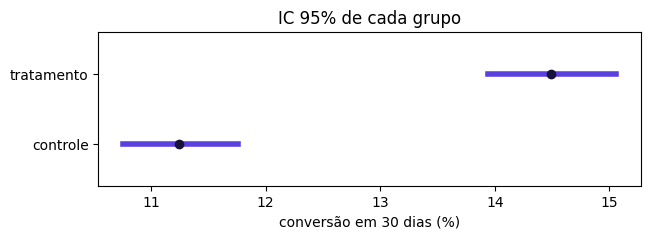

In [ ]:
x1, n1 = ctrl["comprou_30d"].sum(), len(ctrl)
x2, n2 = trat["comprou_30d"].sum(), len(trat)
p1_hat = x1 / n1
p2_hat = x2 / n2

ic1 = proportion_confint(x1, n1, alpha=ALPHA, method="wilson")
ic2 = proportion_confint(x2, n2, alpha=ALPHA, method="wilson")
print(f"Controle:   {p1_hat:.2%}  IC 95% [{ic1[0]:.2%} ; {ic1[1]:.2%}]")
print(f"Tratamento: {p2_hat:.2%}  IC 95% [{ic2[0]:.2%} ; {ic2[1]:.2%}]")

plt.figure(figsize=(7, 2))
plt.plot([ic1[0] * 100, ic1[1] * 100], [0, 0], color="#5B3FE0", linewidth=4)
plt.plot([ic2[0] * 100, ic2[1] * 100], [1, 1], color="#5B3FE0", linewidth=4)
plt.plot([p1_hat * 100, p2_hat * 100], [0, 1], "o", color="#17123B")
plt.yticks([0, 1], ["controle", "tratamento"])
plt.ylim(-0.6, 1.6)
plt.xlabel("conversão em 30 dias (%)")
plt.title("IC 95% de cada grupo")
plt.show()

> **Leitura.** Aqui os intervalos nem se encostam, então a conclusão parece fácil. Mas lembre da aula: **“os intervalos se sobrepõem, então não há diferença” é uma leitura errada**. Dois ICs podem se sobrepor e a diferença ainda ser significativa. Comparar grupos exige olhar para a **diferença** entre eles, com a incerteza da própria diferença.

### 5.2 Lente 1 · O IC da diferença

O parâmetro agora é δ = p_trat − p_ctrl. As variâncias dos dois grupos se somam:

$$\text{EP} = \sqrt{\frac{\hat{p}_1(1-\hat{p}_1)}{n_1} + \frac{\hat{p}_2(1-\hat{p}_2)}{n_2}} \qquad \text{IC} = \hat{\delta} \pm z_{1-\alpha/2} \cdot \text{EP}$$

Essa é a versão de Wald. O método de **Newcombe** (que combina os ICs de Wilson de cada grupo) é mais confiável em amostras pequenas e taxas extremas; aqui os dois coincidem, e usamos o de Newcombe na decisão.

**Prompt para a IA**

> Calcule a diferença de conversão entre tratamento e controle, em pontos percentuais, e o lift relativo. Calcule o intervalo de confiança de 95% dessa diferença por dois métodos, Wald e Newcombe, para comparar. Vamos usar o de Newcombe nas próximas etapas.

In [ ]:
dif = p2_hat - p1_hat
print(f"Diferença: {dif * 100:+.2f} p.p. · lift relativo: {dif / p1_hat:+.1%}")

ic_wald = confint_proportions_2indep(x2, n2, x1, n1, method="wald")
ic_dif = confint_proportions_2indep(x2, n2, x1, n1, method="newcomb")
print(f"IC 95% Wald:     {ic_wald[0] * 100:+.2f} a {ic_wald[1] * 100:+.2f} p.p.")
print(f"IC 95% Newcombe: {ic_dif[0] * 100:+.2f} a {ic_dif[1] * 100:+.2f} p.p.")

Diferença: +3.25 p.p. · lift relativo: +28.9%
IC 95% Wald:     +2.50 a +4.00 p.p.
IC 95% Newcombe: +2.50 a +4.00 p.p.


### 5.3 Lente 2 · O teste de hipótese no multiverso de H0

H0: p_trat = p_ctrl · Ha: p_trat ≠ p_ctrl (bicaudal). No multiverso de H0 as duas taxas são iguais, então estimamos a taxa comum juntando os grupos: é o EP **combinado**.

$$z = \frac{\hat{p}_2 - \hat{p}_1}{\sqrt{\hat{p}(1-\hat{p})\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}, \qquad \hat{p} = \frac{x_1 + x_2}{n_1 + n_2}$$

O teste usa o EP **combinado** (calculado dentro do multiverso de H0); o IC usa o EP **separado** de cada grupo (não supõe H0).

**Prompt para a IA**

> Faça o teste z para duas proporções, bicaudal, comparando a conversão do tratamento com a do controle (H0: as taxas são iguais). Mostre a estatística z e o p-valor.

In [ ]:
z_prop, p_prop = proportions_ztest([x2, x1], [n2, n1])
print(f"z = {z_prop:.2f} · p-valor = {p_prop:.2g}")

z = 8.47 · p-valor = 2.5e-17


### 5.4 Significância estatística e significância prática

O p-valor respondeu “é real?”. Falta “vale a pena?”. A tabela da aula compara o IC com o **zero** e com o **MDE**:

| O que o IC mostra | Leitura | Decisão típica |
|:---|:---|:---|
| Exclui o zero e está todo além do MDE | Real e relevante | Lançar |
| Exclui o zero, mas fica aquém do MDE | Real, pequeno demais | Não lançar (ou rever custo) |
| Inclui o zero, estreito, aquém do MDE | Se houver, não importa | Não lançar |
| Inclui o zero, largo, alcança o MDE | Inconclusivo | Mais amostra ou investigar |

> **Leitura.** A trilha guiada aumentou a conversão em 30 dias de **~11,3% para ~14,5%**, uma diferença de cerca de **+3,2 p.p.** (lift de ~29%).

> O IC de 95% vai de **~+2,5 a ~+4,0 p.p.**. Ele exclui o zero (significância estatística) **e** está todo acima do MDE de 1,5 p.p. (significância prática). É a primeira linha da tabela: **efeito real e relevante**.

## Parte 6 · Métrica secundária: receita por usuário

H0: μ_trat = μ_ctrl · Ha: μ_trat ≠ μ_ctrl (bicaudal).

### 6.1 Resumo dos grupos

**Prompt para a IA**

> Agora a métrica secundária, receita por usuário em 30 dias. Mostre, para cada grupo, o número de usuários, a média, o desvio-padrão, a porcentagem de usuários com receita zero e os percentis 90 e 95.

In [ ]:
mc = ctrl["receita_30d"]
mt = trat["receita_30d"]

resumo = exp.groupby("grupo")["receita_30d"].agg(["count", "mean", "std"])
resumo["% zeros"] = exp.groupby("grupo")["receita_30d"].apply(lambda r: (r == 0).mean())
resumo["p90"] = exp.groupby("grupo")["receita_30d"].quantile(0.90)
resumo["p95"] = exp.groupby("grupo")["receita_30d"].quantile(0.95)
resumo

,count,mean,std,% zeros,p90,p95
grupo,,,,,,
controle,15331,26.960929,88.748345,0.887548,97.0,197.0
tratamento,15167,28.220676,80.772086,0.855080,97.0,197.0


### 6.2 O teste t de Welch

$$t = \frac{\bar{x}_2 - \bar{x}_1}{\sqrt{\frac{s_1^2}{n_1} + \frac{s_2^2}{n_2}}}, \qquad gl = \frac{(a + b)^2}{\frac{a^2}{n_1 - 1} + \frac{b^2}{n_2 - 1}}, \quad a = \frac{s_1^2}{n_1}, \ b = \frac{s_2^2}{n_2}$$

Welch é o padrão: não supõe variâncias iguais e quase não perde poder quando elas são iguais. A checagem de Kohavi da Parte 3 garante que, com este n, a média da receita já se comporta como Normal, apesar dos zeros e da cauda longa.

**Prompt para a IA**

> Calcule a diferença de receita média por usuário (tratamento − controle) e faça o teste t de Welch, bicaudal (H0: as médias são iguais). Mostre a estatística t, os graus de liberdade, o p-valor e o intervalo de confiança de 95% da diferença. Para comparar, rode também o teste t de Student (que supõe variâncias iguais) e mostre t e p-valor.

In [ ]:
dif_m = mt.mean() - mc.mean()

res_welch = stats.ttest_ind(mt, mc, equal_var=False)
ic_m = res_welch.confidence_interval(confidence_level=1 - ALPHA)
print(f"Diferença: R$ {dif_m:+.2f}")
print(f"Welch:   t = {res_welch.statistic:.2f} · gl = {res_welch.df:.0f} · p-valor = {res_welch.pvalue:.3f}")
print(f"IC 95%: R$ {ic_m.low:+.2f} a R$ {ic_m.high:+.2f}")

res_student = stats.ttest_ind(mt, mc, equal_var=True)
print(f"Student: t = {res_student.statistic:.2f} · p-valor = {res_student.pvalue:.3f}")

Diferença: R$ +1.26
Welch:   t = 1.30 · gl = 30286 · p-valor = 0.195
IC 95%: R$ -0.64 a R$ +3.16
Student: t = 1.30 · p-valor = 0.195


> **Leitura.** Welch e Student dão praticamente o mesmo resultado: grupos grandes e do mesmo tamanho. A receita por usuário subiu cerca de **R$ 1,30**, com p ≈ 0,2: o valor observado cai **fora** da região crítica, numa zona que o acaso produz com frequência. Não rejeitamos H0. Mas o IC vai de **~−R$ 0,60 a ~+R$ 3,20**: ele inclui o zero **e** alcança o MDE de R$ 3. É a última linha da tabela: **inconclusivo**. Não é “a trilha não muda a receita”; é “ainda não sabemos”.
>
> Repare no contraste com a conversão: **mais gente comprou, mas a receita não acompanhou na mesma proporção**. Um aumento de ~29% nos compradores viraria, com o mesmo gasto por comprador, ~R$ 8 a mais por usuário. Algo está segurando a receita. A seção 6.4 investiga.

> **Prompt:** No experimento, quero entender em que faixa de gasto estão os compradores a mais do tratamento. Olhando só quem comprou, mostre por grupo o número de compradores, o gasto médio, o número médio de cursos, o preço médio por curso e a porcentagem que comprou só um curso de R$ 97.

In [ ]:
compradores = exp[exp["comprou_30d"] == 1].copy()
compradores["preco_medio_curso"] = compradores["receita_30d"] / compradores["cursos_comprados_30d"]

# Perfil de quem comprou
resumo = compradores.groupby("grupo").agg(
    compradores=("user_id", "count"),
    gasto_medio=("receita_30d", "mean"),
    cursos_medio=("cursos_comprados_30d", "mean"),
    preco_medio_curso=("preco_medio_curso", "mean"),
)
resumo["% só 1 curso de R$ 97"] = compradores.groupby("grupo")["receita_30d"].apply(lambda r: (r == 97).mean() * 100)
print(resumo.round(2))



            compradores  gasto_medio  cursos_medio  preco_medio_curso  \
grupo                                                                   
controle           1724       239.76          1.39             170.93   
tratamento         2198       194.73          1.32             146.81   

            % só 1 curso de R$ 97  
grupo                              
controle                    17.40  
tratamento                  33.94  


manter a trilha, mas destacar também os cursos mais completos, ou oferecer um segundo curso depois da compra do de entrada. A métrica primária desse teste seria a receita por usuário.

### 6.4 Diagnóstico


- **Conclusão da 1ª aula nos 7 dias:** é calculada para todo usuário sorteado, então pode ser testada como qualquer outra métrica. Ela diz se a trilha fez o que prometia no período grátis.


**Prompt para a IA**

> Primeiro, compare a taxa de conclusão da primeira aula nos 7 dias entre tratamento e controle, com o teste z para duas proporções (bicaudal) e o intervalo de confiança de 95% da diferença (wald).


In [ ]:
xa1, xa2 = ctrl["concluiu_aula1_7d"].sum(), trat["concluiu_aula1_7d"].sum()
_, p_at = proportions_ztest([xa2, xa1], [n2, n1])
ic_at_dif = confint_proportions_2indep(xa2, n2, xa1, n1, method="wald")
print(f"Conclusão da 1ª aula: controle {xa1 / n1:.1%} · tratamento {xa2 / n2:.1%}")
print(f"Diferença: {(xa2 / n2 - xa1 / n1) * 100:+.1f} p.p. · p-valor = {p_at:.2g} · IC 95% [{ic_at_dif[0] * 100:+.1f} ; {ic_at_dif[1] * 100:+.1f}] p.p.")
print()


Conclusão da 1ª aula: controle 29.7% · tratamento 37.0%
Diferença: +7.3 p.p. · p-valor = 1.5e-41 · IC 95% [+6.2 ; +8.3] p.p.



> **Leitura.** A trilha fez o que prometia no período grátis: a conclusão da primeira aula subiu cerca de **7 p.p.**. E mais gente comprou. Mas, entre quem comprou, o tratamento gasta **menos** por pessoa: compra menos cursos e cursos mais baratos. **Uma hipótese: a trilha traz para a compra usuários que antes não comprariam, e eles começam pelo curso de entrada.**
>

## Parte 8 · A decisão

**Prompt para a IA**

> Monte a tabela final do relatório, com uma linha para cada métrica (conversão e receita por usuário) e as colunas: controle, tratamento, diferença, IC de 95%, p-valor, MDE e a leitura pela tabela de significância prática. Formate os números para facilitar a leitura.

**Que erro podemos ter cometido?**

| Métrica | Decisão | Erro possível | O que sabemos |
|:---|:---|:---|:---|
| Conversão | Rejeitamos H0 | Só o **tipo I** (falso positivo) | O procedimento erra assim em 5% das vezes quando H0 é verdadeira. Isso **não** quer dizer que o p-valor é a chance de termos errado. |
| Receita | Não rejeitamos H0 | Só o **tipo II** (falso negativo) | Se houver efeito, o IC diz que ele está entre ~−R$ 0,60 e ~+R$ 3,20 por usuário. |

**Recomendação.** Lançar a trilha guiada, acompanhando a receita.

- A **métrica primária**, que decide, mostra um efeito real e relevante: a conversão em 30 dias subiu cerca de 3 p.p., com IC todo acima do MDE de 1,5 p.p.
- A **métrica secundária** é inconclusiva: a receita por usuário pode não ter mudado ou pode ter subido até ~R$ 3. Não há sinal de piora relevante (o pior cenário plausível é uma queda de ~R$ 0,60 por usuário), então ela não impede o lançamento.
- **Próximo passo:** o diagnóstico mostra que a trilha traz mais compradores, mas que eles começam por cursos mais baratos. Mais compradores hoje podem virar mais receita depois (segunda compra). Vale acompanhar a receita em uma janela mais longa e testar, em seguida, uma recomendação de cursos após a primeira compra.

